# StockSense - Round 2: Feature Engineering & Demand Forecasting
**Student 2 - ML Engineer** · IntelliData 2026 · NovaMart Retail

Scope from the brief (section 10): *feature engineering, forecasting, validation*.

| Step | What | Code |
|---|---|---|
| 1 | Build one row per forecast origin (close of day *t*, store x product) with 61 leakage-free features and the targets for both models | `src/features.py` |
| 2 | Prove there is no leakage | `features.check_no_leakage()` |
| 3 | Time-aware split with gaps | `src/train_forecast.py` |
| 4 | Baseline, then all permitted regression algorithms, tuned on validation | `train_forecast.tune()` |
| 5 | Test scored once; metrics MAE, RMSE, MAPE, R², WAPE, bias | `train_forecast.evaluate_on_test()` |
| 6 | Residual analysis and permutation importance | |
| 7 | Final model, forecast for 1-7 Sep, out-of-time forecasts for Model 2 | `models/`, `data/processed/` |

The notebook calls the same functions as the scripts, so there is one source of truth. Input: Round 1's `data/processed/` tables.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
import features as F
import train_forecast as TF
pd.set_option("display.width", 200, "display.max_columns", 40)
FIG = ROOT / "reports" / "figures"

## 1. The modelling table: one row per forecast origin

Every evening after closing, for every store x product, the system predicts demand for *t+1 ... t+7*. That moment defines what is "known":
sales, stock and weather up to *t*, purchase orders placed by *t* (with their **expected** date), and calendars published in advance
(planned promotions, holidays, festivals, local events, paydays).

Both targets sit on the same row, so Model 1 and Model 2 describe the same week:
- `next_7_day_demand` = sum of `demand_est` over *t+1..t+7* (Model 1). `demand_est`, not raw sales: on stock-out days sales are capped by the empty shelf.
- `stockout_next7` = 1 if closing stock hits 0 on any day in *t+1..t+7* (Model 2, Student 3).

In [2]:
m, promos, weather, po = F.load_inputs()
feat = F.build_features(m, promos, weather, po)
print(f"{len(feat):,} origin rows x {len(F.FEATURES)} features")
pd.DataFrame([(g, len(c), ", ".join(c)) for g, c in F.FEATURE_GROUPS.items()],
             columns=["group", "n", "features"])

69,554 origin rows x 61 features


,group,n,features
0,Recent demand,13,"lag_1, lag_7, lag_14, rolling_mean_7, rolling_..."
1,Promotion plan,8,"promo_days_next7, max_discount_next7, avg_disc..."
2,Festival & holiday calendar,7,"holiday_next7, festival_next7, days_to_festiva..."
3,Weather,3,"temp_last3, rain_last3, temp_anomaly"
4,Price,4,"regular_price, price_ratio_28, price_change_30..."
5,Stock & supply,16,"closing_stock, reorder_level, reorder_gap, inc..."
6,Store & product profile,8,"store_code, store_type, category, sub_category..."
7,Calendar position,2,"origin_dow, month"


Example: Chennai hypermarket, Cola 750 ml, close of 10 June. The item is out of stock that day, 768 units are on order from
SUP04 (late on about a third of its orders), a promotion has just ended (post-promotion dip), and the 1 June MRP hike shows as +9% price change.

In [3]:
feat[(feat.store_id == "S02") & (feat.product_id == "P330") & (feat.date == "2026-06-10")][
    ["date", "store_id", "product_name"] + F.FEATURES + ["next_7_day_demand", "stockout_next7"]].T

,16715
date,2026-06-10 00:00:00
store_id,S02
product_name,Cola 750ml
lag_1,59
lag_7,90.0
...,...
history_days,102
origin_dow,2
month,6
next_7_day_demand,590.0


## 2. Proof of no leakage

The brief: *any feature used to predict the future must contain only information available at prediction time.*
For four origin dates, everything observed after *t* is deleted (sales, stock, weather, PO arrivals), the features are
rebuilt, and each of the 61 features must be identical to the full-data version. Two real leaks were caught this way
while building the table (a festival profile learned over the whole period, and festival dates read from sales data
instead of the published calendar); both were fixed.

In [4]:
n = F.check_no_leakage(m, promos, weather, po, feat)
print(f"{n:,} origin rows rebuilt from truncated data - all {len(F.FEATURES)} features identical. No leakage.")

1,516 origin rows rebuilt from truncated data - all 61 features identical. No leakage.


In [5]:
F.main()   # saves data/processed/features.csv and reports/feature_dictionary.md

Loading processed data ...


Building features ...


Checking for leakage ...


  1516 origin rows rebuilt from truncated data: all 61 features identical


features.csv: 69,554 origin rows x 61 features (66,849 with a complete 7-day target; origins 2026-03-01 .. 2026-08-31)
stockout_next7 positive rate: 28.2%


,date,store_id,product_id,product_name,category_name,store_type_name,city,supplier_id,sparse_history_flag,unit_price,cost_price,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_std_7,rolling_std_28,cv_28,...,regular_price,price_ratio_28,price_change_30d,discount_today,store_code,store_type,category,sub_category,shelf_life_days,mrp,avg_daily_customers,floor_area_sqft,history_days,product_festival_lift,festival_x_lift,next_7_day_demand,next_7_day_units_sold,stockout_next7,stockout_days_next7,lost_units_next7
0,2026-03-01,S01,P101,Milk 1L,Dairy,Supermarket,Coimbatore,SUP01,0,54.0,52,103,NaN,NaN,103.000000,103.000000,103.000000,NaN,NaN,NaN,...,54.0,1.0,0.0,0.0,1,Supermarket,Dairy,Milk,3,60,1250,8500,1,1.000000,0.000000,524.0,524.0,0.0,0.0,0.0
1,2026-03-02,S01,P101,Milk 1L,Dairy,Supermarket,Coimbatore,SUP01,0,54.0,52,54,NaN,NaN,78.500000,78.500000,78.500000,34.648232,34.648232,0.441379,...,54.0,1.0,0.0,0.0,1,Supermarket,Dairy,Milk,3,60,1250,8500,2,1.000000,0.000000,531.0,531.0,0.0,0.0,0.0
2,2026-03-03,S01,P101,Milk 1L,Dairy,Supermarket,Coimbatore,SUP01,0,54.0,52,76,NaN,NaN,77.666667,77.666667,77.666667,24.542480,24.542480,0.315998,...,54.0,1.0,0.0,0.0,1,Supermarket,Dairy,Milk,3,60,1250,8500,3,1.000000,0.000000,501.0,501.0,0.0,0.0,0.0
3,2026-03-04,S01,P101,Milk 1L,Dairy,Supermarket,Coimbatore,SUP01,0,54.0,52,82,NaN,NaN,78.750000,78.750000,78.750000,20.155644,20.155644,0.255945,...,54.0,1.0,0.0,0.0,1,Supermarket,Dairy,Milk,3,60,1250,8500,4,1.000000,0.000000,500.0,500.0,0.0,0.0,0.0
4,2026-03-05,S01,P101,Milk 1L,Dairy,Supermarket,Coimbatore,SUP01,0,54.0,52,57,NaN,NaN,74.400000,74.400000,74.400000,19.982492,19.982492,0.268582,...,54.0,1.0,0.0,0.0,1,Supermarket,Dairy,Milk,3,60,1250,8500,5,1.000000,0.000000,505.0,505.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69549,2026-08-27,S06,P706,Kulfi Stick,Frozen,Express,Chennai,SUP09,0,29.0,18,13,3.0,6.0,7.714286,8.928571,7.750000,5.559205,4.948812,0.638556,...,29.0,1.0,0.0,0.0,6,Express,Frozen,Ice Cream,180,30,760,3900,180,1.018557,0.018557,NaN,NaN,NaN,NaN,NaN
69550,2026-08-28,S06,P706,Kulfi Stick,Frozen,Express,Chennai,SUP09,0,29.0,18,5,3.0,11.0,8.000000,8.857143,7.714286,5.322906,4.965489,0.643675,...,29.0,1.0,0.0,0.0,6,Express,Frozen,Ice Cream,180,30,760,3900,181,1.007906,0.007906,NaN,NaN,NaN,NaN,NaN
69551,2026-08-29,S06,P706,Kulfi Stick,Frozen,Express,Chennai,SUP09,0,29.0,18,16,14.0,17.0,9.857143,9.214286,7.928571,5.550633,5.192078,0.654857,...,29.0,1.0,0.0,0.0,6,Express,Frozen,Ice Cream,180,30,760,3900,182,1.008728,0.008728,NaN,NaN,NaN,NaN,NaN
69552,2026-08-30,S06,P706,Kulfi Stick,Frozen,Express,Chennai,SUP09,0,29.0,18,7,13.0,16.0,8.857143,8.500000,8.107143,5.304984,5.065053,0.624764,...,29.0,1.0,0.0,0.0,6,Express,Frozen,Ice Cream,180,30,760,3900,183,1.010610,0.010610,NaN,NaN,NaN,NaN,NaN


## 3. Time-aware split

No random shuffling. Between splits there is a **7-day gap in origins**: a training origin on 12 Jul has a target covering
13-19 Jul, so validation starts on 20 Jul. Without the gap, validation days would sit inside training targets
(leakage through the label).

In [6]:
pd.DataFrame([(k, a.date(), b.date(), (b + pd.Timedelta(days=7)).date(), len(TF.between(feat, (a, b))))
              for k, (a, b) in TF.SPLITS.items()],
             columns=["split", "first origin", "last origin", "target windows end", "rows"])

,split,first origin,last origin,target windows end,rows
0,train,2026-03-08,2026-07-12,2026-07-19,47879
1,validation,2026-07-20,2026-08-03,2026-08-10,5655
2,test,2026-08-11,2026-08-24,2026-08-31,5390


## 4. Train, tune and compare

Baseline first (the brief's *previous 7-day mean*), then every permitted regression algorithm: Linear Regression, Decision Tree,
Random Forest, XGBoost, KNN and SVM (Naive Bayes is a classifier, so it does not apply). Each is tuned on **validation only**.
The best configuration of each is refitted on train + validation and the **test set is scored once**.
The model is chosen on validation WAPE.

This cell runs the full pipeline (about 10 minutes): tuning, test, importance, final refit, out-of-time forecasts, reports.

In [7]:
out = TF.main()

Rows - train 47,879 | validation 5,655 | test 5,390 | final 387
Tuning on validation ...


  Linear Regression  OLS on log target                                              WAPE 0.153  (1s)


  Decision Tree      max_depth=6, min_samples_leaf=5                                WAPE 0.173  (1s)


  Decision Tree      max_depth=6, min_samples_leaf=20                               WAPE 0.172  (1s)


  Decision Tree      max_depth=6, min_samples_leaf=50                               WAPE 0.174  (1s)


  Decision Tree      max_depth=8, min_samples_leaf=5                                WAPE 0.174  (1s)


... (52 outputs left out)

  origins 2026-08-30 .. 2026-08-30: trained on 63,440 rows


Scoring against the answer key (evaluation only) ...


Charts and report ...


Done. Test WAPE 15.3% vs baseline 20.8%
Holdout week 1-7 Sep vs true demand: WAPE 14.7% (baseline 19.3%)


In [8]:
tuning = out["tuning"]
tuning.assign(**{c: tuning[c].round(3) for c in ["WAPE", "MAPE", "R2", "Bias"]}).sort_values("WAPE").head(15)

,algorithm,config,WAPE,MAE,RMSE,MAPE,R2,Bias,fit_seconds
34,XGBoost,"squared error on log target, max_depth=5, min_...",0.149,17.262347,30.351755,0.181,0.959,-0.033,4.853588
30,XGBoost,"tweedie, max_depth=5, min_child_weight=10, tre...",0.150,17.355721,30.578747,0.183,0.958,-0.021,4.501276
33,XGBoost,"squared error on log target, max_depth=5, min_...",0.150,17.331064,30.498029,0.181,0.958,-0.037,3.970161
29,XGBoost,"tweedie, max_depth=5, min_child_weight=1, tree...",0.150,17.344145,30.517135,0.183,0.958,-0.024,4.127428
31,XGBoost,"tweedie, max_depth=7, min_child_weight=1, tree...",0.151,17.517999,31.101260,0.184,0.957,-0.024,4.644253
26,XGBoost,"squared error, max_depth=5, min_child_weight=1...",0.151,17.479640,30.811736,0.185,0.958,-0.013,7.762885
25,XGBoost,"squared error, max_depth=5, min_child_weight=1...",0.151,17.489128,30.729241,0.187,0.958,-0.012,6.313442
1,Linear Regression,OLS on log target,0.153,17.657686,30.116498,0.189,0.959,-0.009,0.745691
41,SVM,"linear kernel, C=0.1",0.153,17.652728,30.236701,0.188,0.959,-0.009,1.099371
32,XGBoost,"tweedie, max_depth=7, min_child_weight=10, tre...",0.153,17.656393,31.448654,0.185,0.956,-0.026,4.019021


In [9]:
res = out["test_res"].sort_values("WAPE")
res.assign(**{c: res[c].round(3) for c in ["WAPE", "MAPE", "R2", "Bias"]}, MAE=res.MAE.round(1), RMSE=res.RMSE.round(1))

,algorithm,WAPE,MAE,RMSE,MAPE,R2,Bias
1,XGBoost,0.153,17.8,34.2,0.183,0.950,-0.045
4,Random Forest,0.158,18.4,34.8,0.199,0.948,-0.015
2,SVM,0.158,18.4,35.2,0.183,0.947,-0.070
3,Linear Regression,0.159,18.4,35.6,0.182,0.946,-0.070
5,Decision Tree,0.172,20.0,39.6,0.211,0.933,-0.037
6,KNN,0.193,22.4,42.7,0.226,0.922,-0.085
0,Baseline (7 x last-7-day mean),0.208,24.2,44.8,0.259,0.914,-0.058


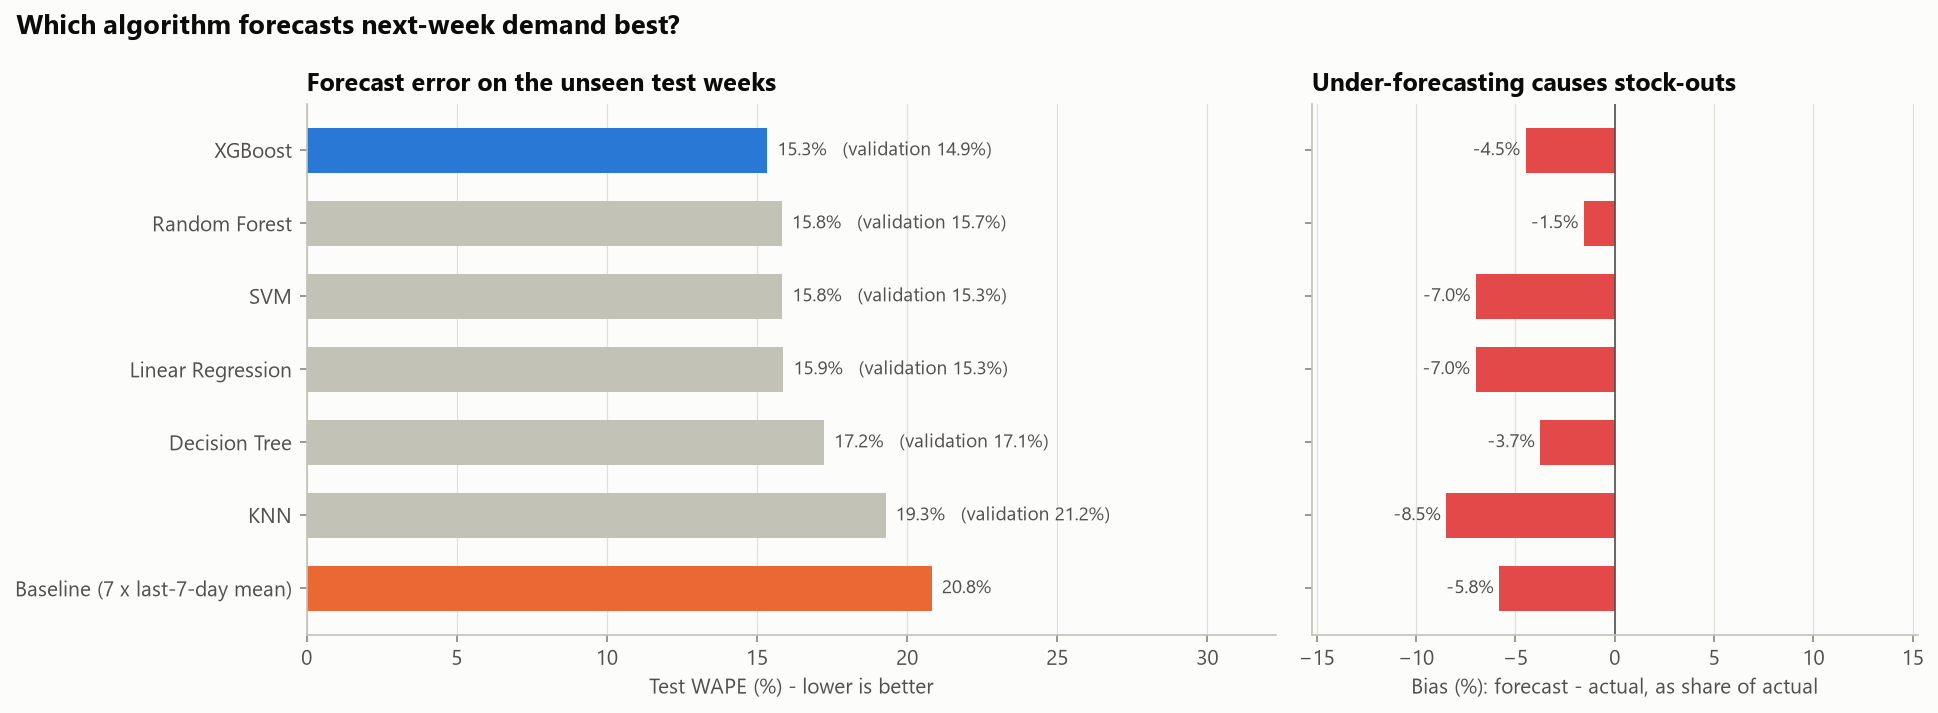

In [10]:
display(Image(FIG / "11_model1_comparison.png"))

### Which metric matters most to the business?
**WAPE** (sum of absolute errors / sum of demand), with **bias** as the second check. WAPE weights errors by volume, so it
tracks money and replenishment effort. MAPE explodes on slow movers (actual 2, forecast 4 = 100% error). Bias matters because a
systematic under-forecast causes stock-outs even when MAE looks fine. Safety stock absorbs random error, not a systematic shortfall.

## 5. Does the forecast track real demand, and where is it weakest?

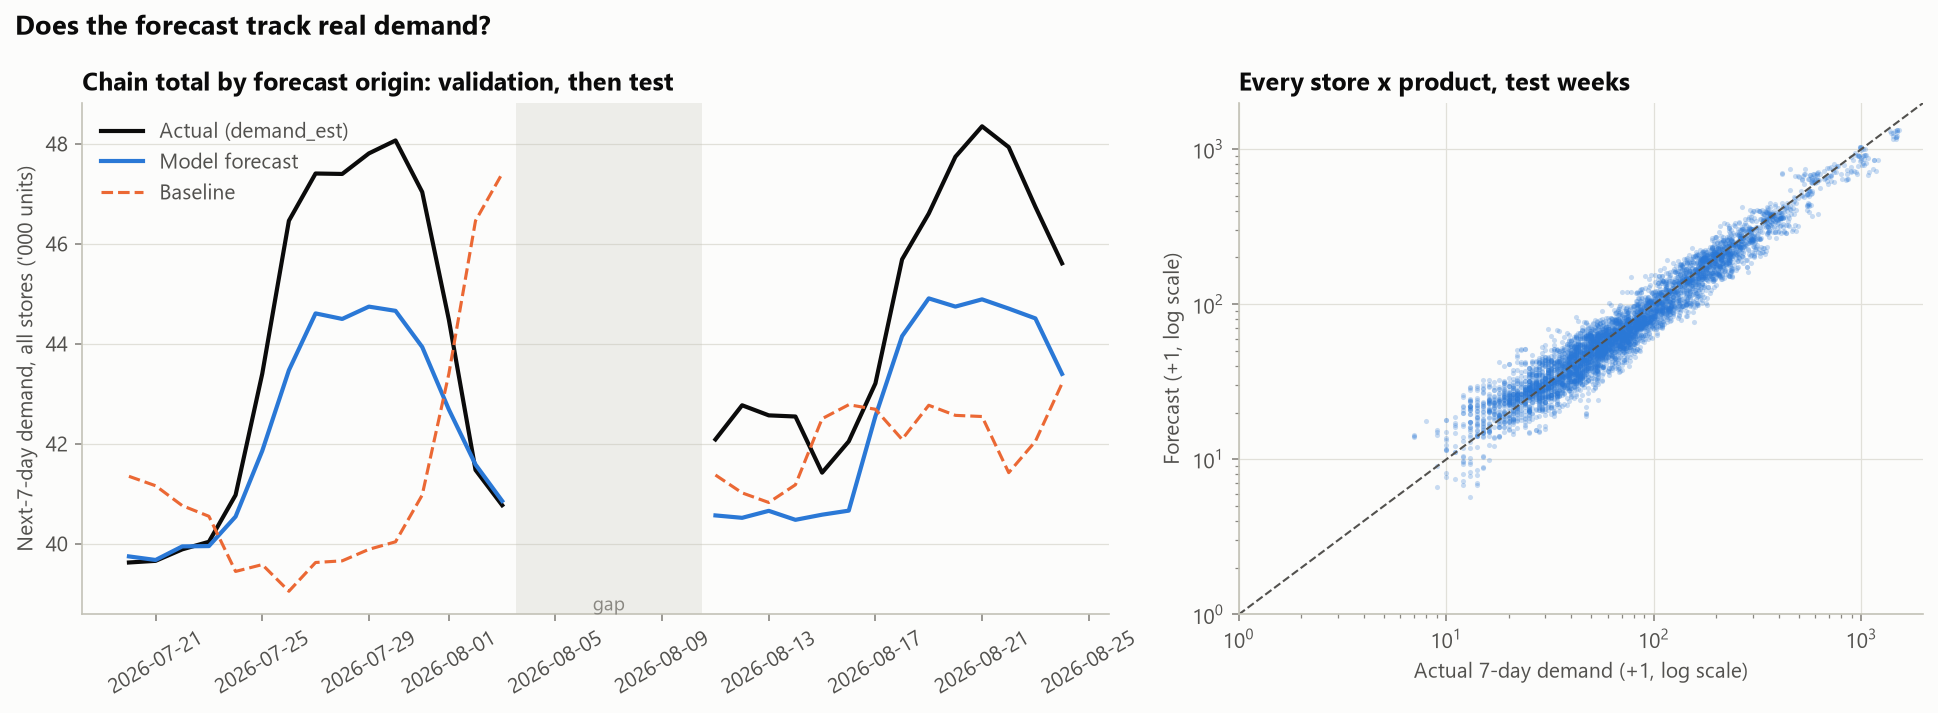

In [11]:
display(Image(FIG / "12_actual_vs_forecast.png"))

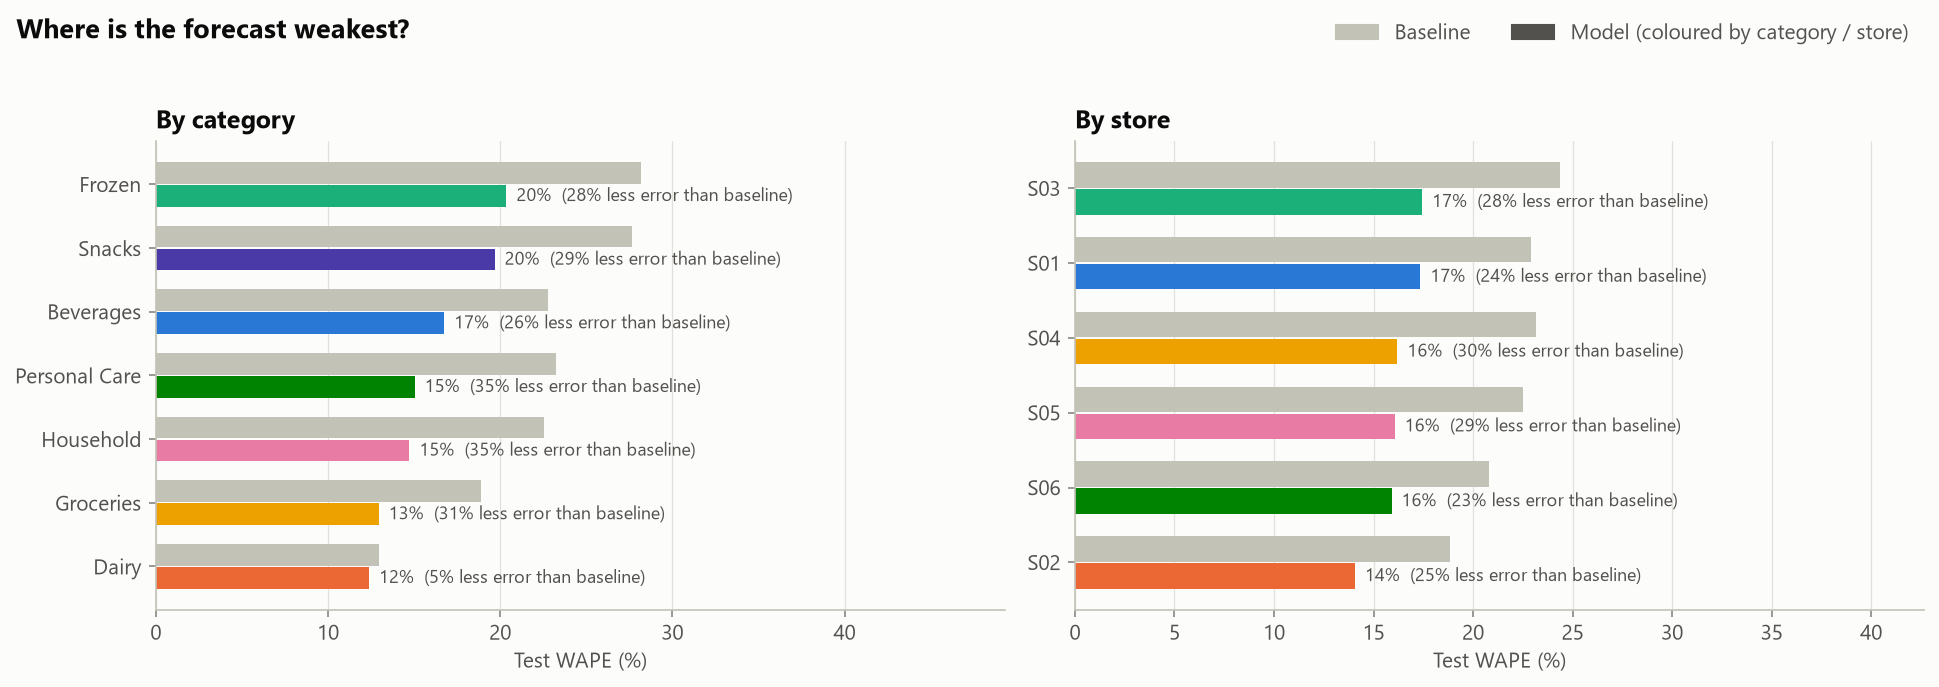

In [12]:
display(Image(FIG / "13_forecast_error_by_segment.png"))

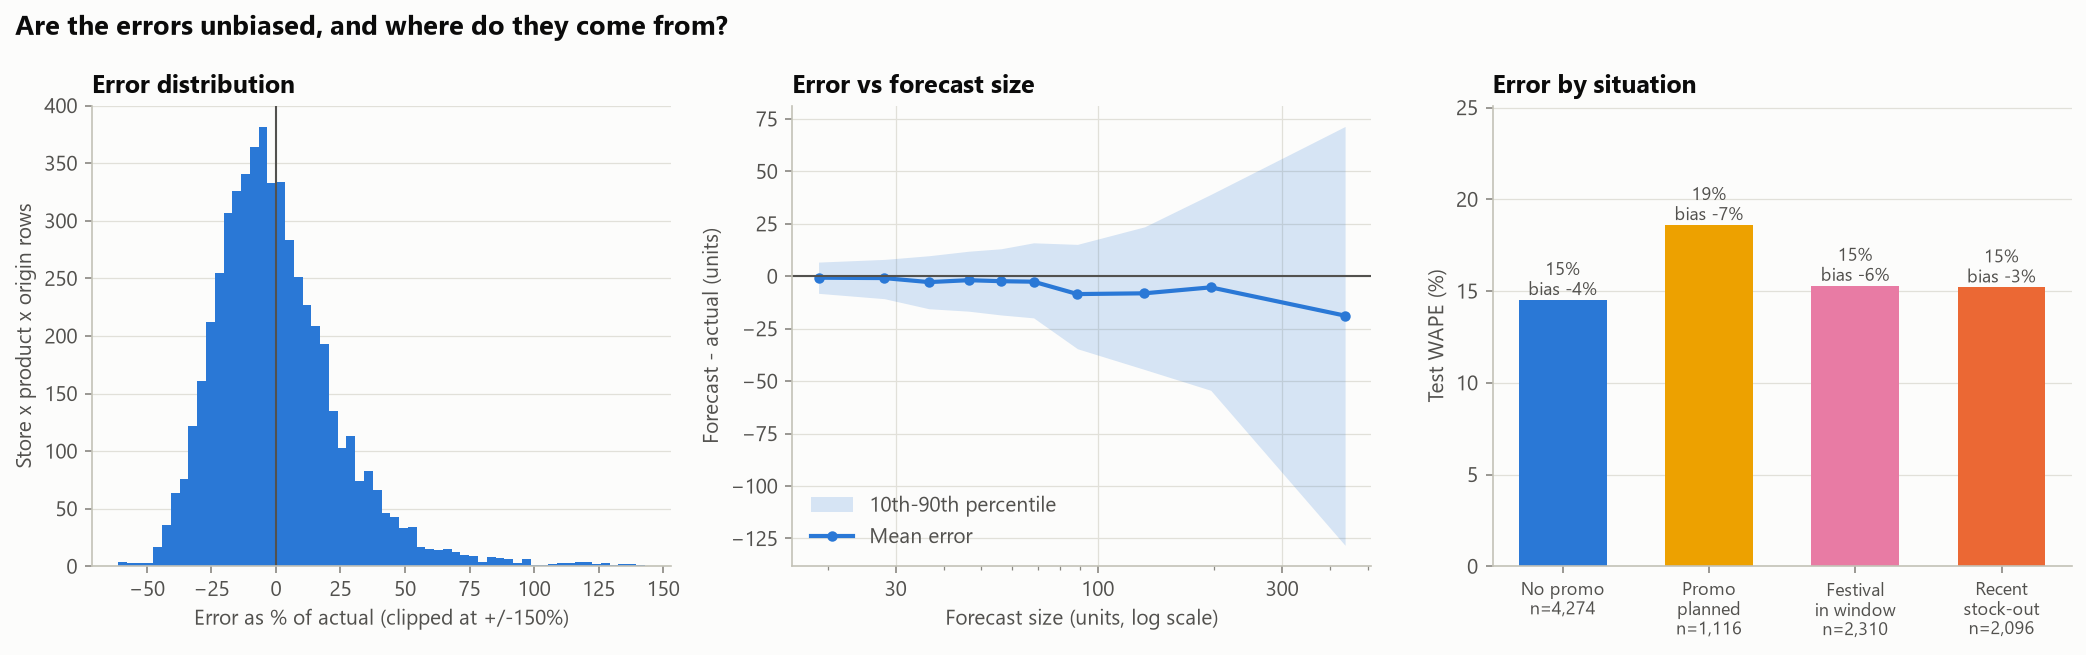

In [13]:
display(Image(FIG / "14_residual_analysis.png"))

## 6. What the model relies on (permutation importance, test set)
Each feature group is shuffled across rows and the increase in WAPE is measured. This shows what the model really uses on unseen data.

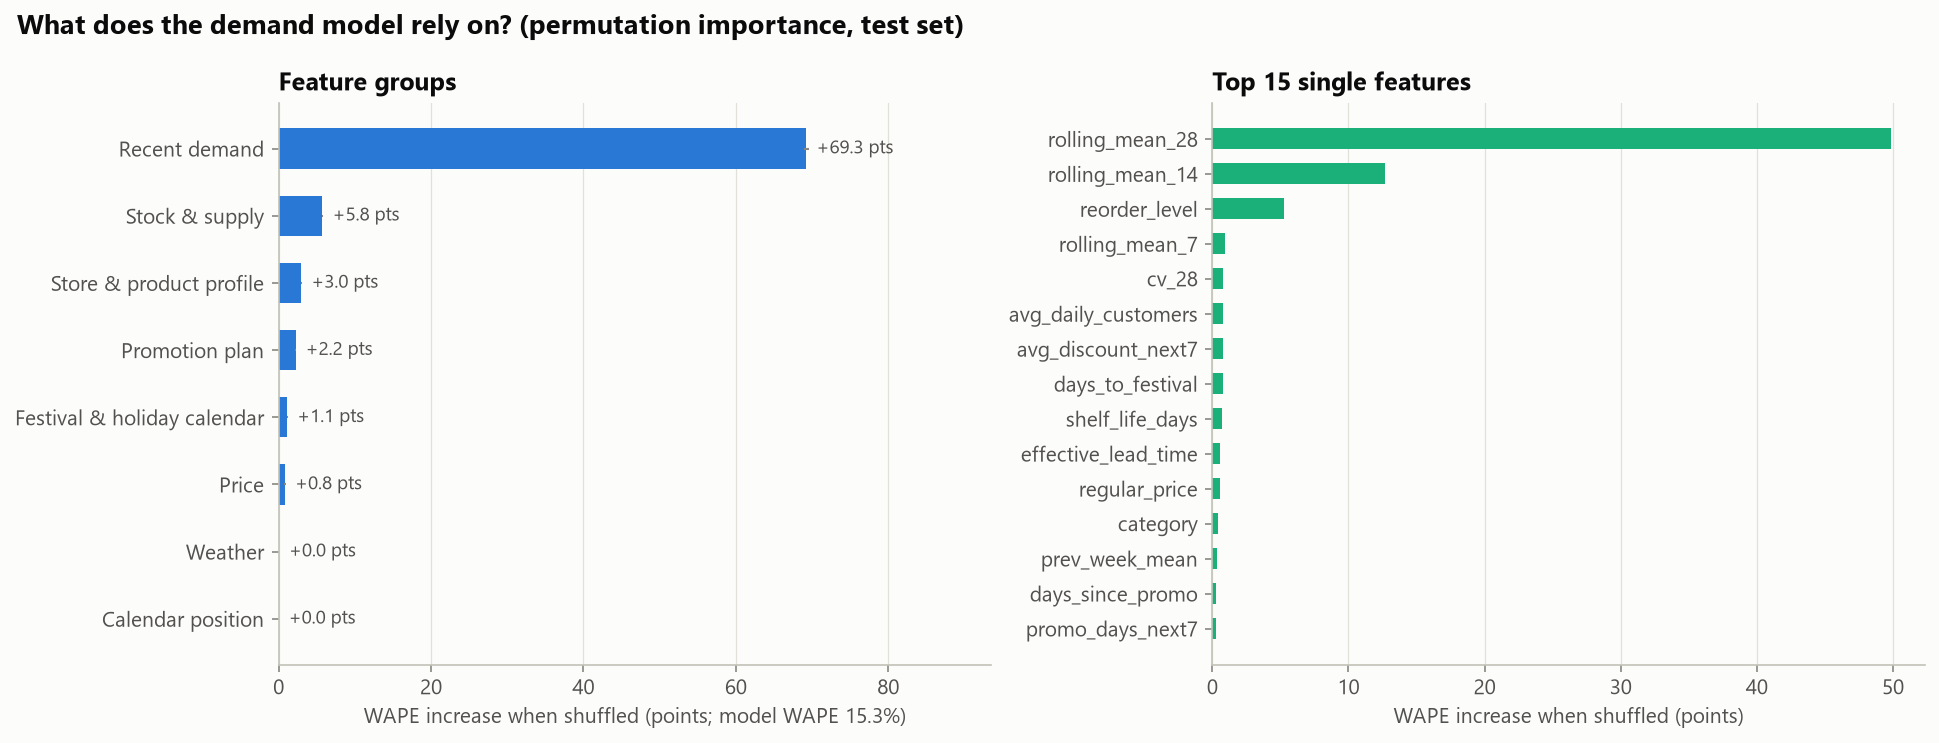

In [14]:
display(Image(FIG / "15_model1_feature_importance.png"))

In [15]:
pd.read_csv(ROOT / "reports" / "model1_feature_importance_groups.csv").round(4)

,feature,wape_increase,std
0,Recent demand,0.6927,0.0030
1,Stock & supply,0.0576,0.0007
2,Store & product profile,0.0298,0.0009
3,Promotion plan,0.0223,0.0012
4,Festival & holiday calendar,0.0112,0.0006
5,Price,0.0084,0.0010
6,Weather,0.0004,0.0001
7,Calendar position,0.0000,0.0000


## 7. Scored against the answer key (evaluation only)
The answer key holds the simulator's true demand. It is git-ignored and was **not** used for training, tuning or selection.
If it is present locally, it checks two claims:
1. training on `demand_est` beats training on raw sales;
2. the forecast holds on the truly unseen week 1-7 Sep.

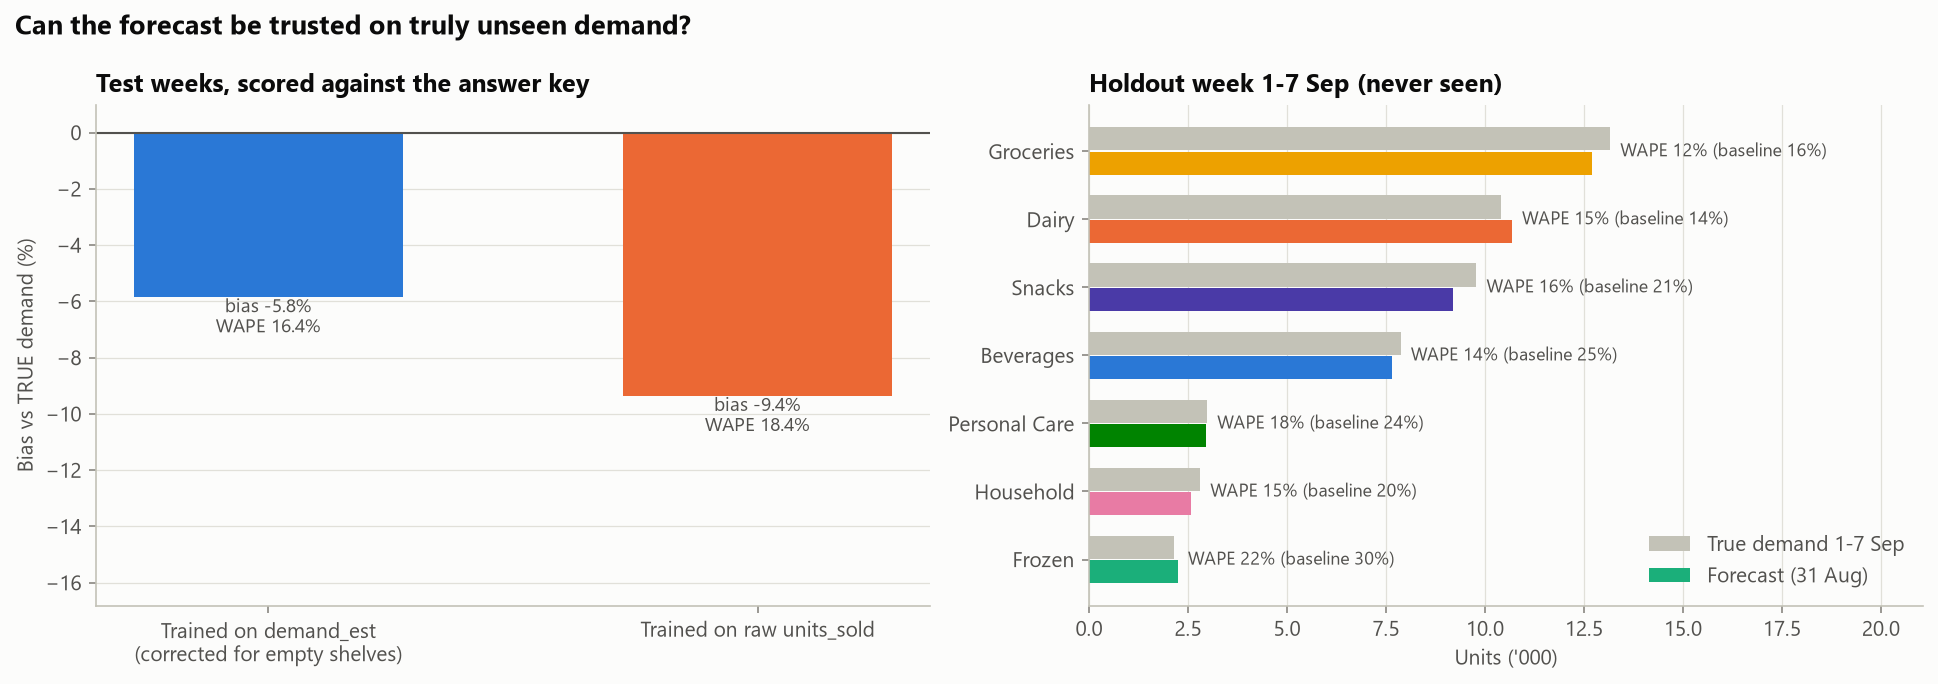

,WAPE,MAE,RMSE,MAPE,R2,Bias
Model trained on demand_est (ours),0.164,19.347,37.859,0.190,0.940,-0.058
Same model trained on raw units_sold,0.184,21.630,45.367,0.197,0.914,-0.094


,WAPE,MAE,RMSE,MAPE,R2,Bias
Model (origin 31 Aug),0.147,18.658,32.817,0.176,0.956,-0.024
Baseline,0.193,24.530,41.036,0.232,0.932,-0.070


In [16]:
p = FIG / "16_answer_key_check.png"
if out["ak"]:
    display(Image(p))
    display(pd.DataFrame(out["ak"]["test_vs_truth"]).T.round(3))
    display(pd.DataFrame(out["ak"]["holdout_week"]).T.round(3))
else:
    print("Answer key not present locally - skipped.")

## 8. Final forecast for 1-7 Sep and hand-off

In [17]:
fc = out["final"].sort_values("forecast_7d", ascending=False)
fc[["store_id", "product_name", "category", "closing_stock", "incoming_next7", "baseline_7d",
    "forecast_7d", "forecast_p10", "forecast_p90"]].head(12)

,store_id,product_name,category,closing_stock,incoming_next7,baseline_7d,forecast_7d,forecast_p10,forecast_p90
12739,S02,Milk 1L,Dairy,314,0.0,1392.0,1339.500000,1175.1,1503.9
12923,S02,Milk 500ml,Dairy,358,0.0,992.0,1043.699951,947.5,1139.9
17533,S02,Packaged Water 1L,Beverages,246,612.0,886.0,937.500000,720.2,1154.7
14395,S02,Bread 400g,Groceries,95,280.0,953.0,905.099976,790.2,1019.9
19027,S02,Potato Chips 52g,Snacks,561,0.0,710.0,733.500000,563.0,904.0
16797,S02,Cola 750ml,Beverages,289,696.0,479.0,719.099976,495.6,942.6
13291,S02,Buttermilk 200ml,Dairy,103,168.0,562.0,680.599976,588.1,773.1
14763,S02,Idli Batter 1kg,Groceries,88,176.0,607.0,674.700012,602.7,746.7
18475,S02,Biscuits 200g,Snacks,101,696.0,610.0,619.500000,466.5,772.6
13107,S02,Curd 500g,Dairy,85,180.0,454.0,577.599976,525.4,629.9


In [18]:
from forecast import load_model, predict
bundle = load_model()
print(bundle["algorithm"], "|", bundle["config"], "| trained on origins", bundle["trained_on_origins"])
today = feat[feat.date == feat.date.max()]
print("re-predicted from the saved model matches the saved forecast:",
      np.allclose(predict(bundle, today), out["final"].forecast_7d, atol=0.051))

XGBoost

 | squared error on log target, max_depth=5, min_child_weight=10, trees=727 | trained on origins ['2026-03-08', '2026-08-24']
re-predicted from the saved model matches the saved forecast: True


**Hand-off to Student 3 (stock-out risk, explainability, recommendation)**
- `data/processed/features.csv`: same origin rows, with the Model 2 target `stockout_next7` (about 28% positive) and all stock, supply and supplier features.
- `data/processed/forecast_oot.csv`: an **out-of-time** 7-day forecast for every origin from 12 Apr. Each 14-day block was predicted by a model trained only on
  earlier targets, so it can be used as a Model 2 feature (e.g. `coverage = (closing_stock + incoming_next7) / forecast_7d`) without leakage.
- `data/processed/forecast_next7.csv`: the 1-7 Sep forecast with an 80% range; `forecast_sigma_7d` feeds safety stock = z x sigma x sqrt((lead + review) / 7).
- `models/demand_forecast.joblib` + `src/forecast.py`: `load_model()` / `predict()` for the dashboard and what-if analysis.
- Full write-up: `reports/model1_demand_forecast.md`; feature list: `reports/feature_dictionary.md`.